In [ ]:
import os, sys, json, logging, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
from scipy.signal import resample_poly
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, f1_score

from utils.helper import save_curves
sys.path.append('../SpikeNet2')
from sleeplib.config import Config
from sleeplib.datasets import BonoboDataset, Hardmine_BonoboDataset
from sleeplib.montages import CDAC_combine_montage
from sleeplib.transforms import cut_and_jitter, channel_flip, extremes_remover
from sleeplib.Resnet_15.model import ResNet

In [2]:
# load config and show all default parameters
config = Config()
config.print_config()
combine_montage = CDAC_combine_montage()

# load dataset
ROOT = '/egr/research-slim/luozishe/IEDClassification/SpikeNet2'
run_name = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
df = pd.read_csv(f'{ROOT}/hf_spikenet/lut_all.csv', sep=';')
checkpoints = f'{Path(os.getcwd())}/checkpoints/{run_name}'
run = f'{Path(os.getcwd())}/run/{run_name}'
os.makedirs(checkpoints, exist_ok=True)
os.makedirs(run, exist_ok=True)

THIS CONFIG FILE CONTAINS THE FOLLOWING PARAMETERS :

PATH_FILES_BONOBO /egr/research-slim/luozishe/IEDClassification/SpikeNet2/hf_spikenet/Events/
PATH_LUT_BONOBO /egr/research-slim/luozishe/IEDClassification/SpikeNet2/hf_spikenet/lut_all.csv
PATH_CONTINOUS_EEG your_path/EEG/hm_negative_eeg/
FQ 128
MONTAGE combine
WINDOWSIZE 1
N_CHANNELS 37
BATCH_SIZE 256
LR 0.0001
MAX_EPOCHS 30
MIN_EPOCHS 10
PATIENCE 5


In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_path, run_path = checkpoints, run
MAX_EPOCHS, MIN_EPOCHS, PATIENCE = 30, 10, 4

log = logging.getLogger(run_name); log.setLevel(logging.INFO); log.handlers.clear()
for h in [logging.StreamHandler(sys.stdout), logging.FileHandler(f'{run_path}/log.txt')]:
    h.setFormatter(logging.Formatter('%(asctime)s %(message)s')); log.addHandler(h)

CLIPS    = config.PATH_FILES_BONOBO
CV_DIR   = f'{ROOT}/hf_spikenet/CV5'; os.makedirs(CV_DIR, exist_ok=True)
CLIP_SEC = ...      # from turn_label.ipynb
ORDER    = ...      # from turn_label.ipynb
log.info(f'device {device} | run {run_name}')

2026-11-22 02:53:04,972 device cuda | run 20261122_025300


In [4]:
df['patient'] = df['eeg_file'].str.split('_Run').str[0]
NO_IED_DIR = Path('/egr/research-slim/shared/hf_dataset/CrossSubject_OUTPUT/no_ied')
ctrl_runs  = sorted(NO_IED_DIR.glob('*/Run*_meta.json'))
CTRL_PTS   = sorted({p.parent.name for p in ctrl_runs})
FP_PT, MINE_PTS = CTRL_PTS[-1], CTRL_PTS[:-1]
print(CTRL_PTS)
print('mine:', MINE_PTS, '| FP/hour:', FP_PT)
df.groupby('patient')['fraction_of_yes'].agg(n='size', n_ieds=lambda x: (x >= 0.5).sum())

['20529', '20535', '20537']
mine: ['20529', '20535'] | FP/hour: 20537


,n,n_ieds
patient,,
20542,12,2
20549,132,22
20551,372,62
20553,96,16
20555,54,9
20556,156,26
20558,228,38
20559,192,32
20561,6,1


31013 mining windows | 14372 FP-eval windows
labeled (50, 256) | control (50, 256)
ctrl_fp                    event_file    eeg_file patient       t  \
0         ctrl_20537_Run1_200  20537_Run1   20537    1.00   
1         ctrl_20537_Run1_250  20537_Run1   20537    1.25   
2         ctrl_20537_Run1_300  20537_Run1   20537    1.50   
3         ctrl_20537_Run1_350  20537_Run1   20537    1.75   
4         ctrl_20537_Run1_400  20537_Run1   20537    2.00   
...                       ...         ...     ...     ...   
14367  ctrl_20537_Run4_179600  20537_Run4   20537  898.00   
14368  ctrl_20537_Run4_179650  20537_Run4   20537  898.25   
14369  ctrl_20537_Run4_179700  20537_Run4   20537  898.50   
14370  ctrl_20537_Run4_179750  20537_Run4   20537  898.75   
14371  ctrl_20537_Run4_179800  20537_Run4   20537  899.00   

       total_votes_received  fraction_of_yes   Mode  
0                         1              0.0  Train  
1                         1              0.0  Train  
2             

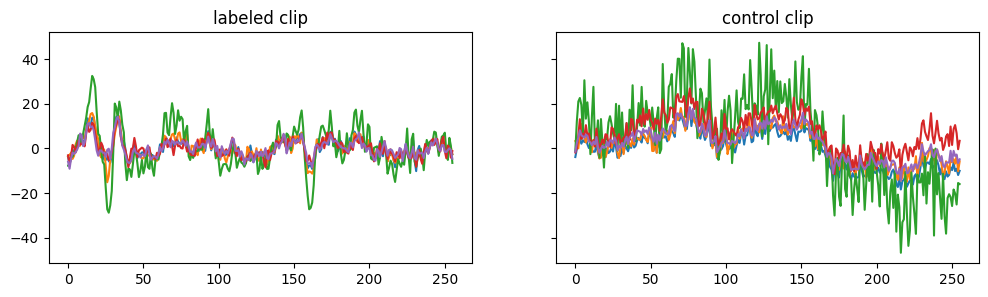

In [5]:
CLIP_SEC = 2.0
ORDER    = list(range(50))

def build_ctrl_lut(pts, stride_sec=0.25):
    rows = []
    for mpath in ctrl_runs:
        pt = mpath.parent.name
        if pt not in pts: continue
        meta = json.load(open(mpath))
        X = np.load(str(mpath).replace('_meta.json', '_X.npy'), mmap_mode='r')
        eeg_file = f"{pt}_Run{meta['run']}"
        fs, N = meta['sfreq'], meta['n_samples']
        half = int(CLIP_SEC / 2 * fs)
        for s in range(half, N - half, int(stride_sec * fs)):
            name = f'ctrl_{eeg_file}_{s}'
            f = f'{CLIPS}/{name}.npy'
            if not os.path.exists(f):
                seg = np.asarray(X[ORDER, s - half:s + half], np.float32)
                np.save(f, resample_poly(seg, 16, 25, axis=-1).astype(np.float32))
            rows.append((name, eeg_file, pt, s / fs))
    return pd.DataFrame(rows, columns=['event_file', 'eeg_file', 'patient', 't']).assign(
        total_votes_received=1, fraction_of_yes=0.0, Mode='Train')

ctrl_mine = build_ctrl_lut(MINE_PTS)      # 20529, 20535
ctrl_fp   = build_ctrl_lut([FP_PT])       # 20537
print(len(ctrl_mine), 'mining windows |', len(ctrl_fp), 'FP-eval windows')

lab = np.load(f"{CLIPS}/{df['event_file'].iloc[0]}.npy")
c   = np.load(f"{CLIPS}/{ctrl_mine['event_file'].iloc[0]}.npy")
print('labeled', lab.shape, '| control', c.shape)
print("ctrl_fp", ctrl_fp)
fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
ax[0].plot(lab[:5].T); ax[0].set_title('labeled clip'); ax[1].plot(c[:5].T); ax[1].set_title('control clip'); plt.show()

In [6]:
print(len(df), 'labeled windows')
print(f"ctrl_mine: {len(ctrl_mine)} windows | ctrl_fp: {len(ctrl_fp)} windows")
print(f"ctrl_mine: {ctrl_mine['patient'].nunique()} patients | ctrl_fp: {ctrl_fp['patient'].nunique()} patients")

1314 labeled windows
ctrl_mine: 31013 windows | ctrl_fp: 14372 windows
ctrl_mine: 2 patients | ctrl_fp: 1 patients


In [7]:
FOLDS = {0: dict(test=['20551', '20561'], val=['20558', '20542']),
         1: dict(test=['20558', '20542'], val=['20559', '20555']),
         2: dict(test=['20559', '20555'], val=['20556', '20564']),
         3: dict(test=['20556', '20564'], val=['20549', '20553']),
         4: dict(test=['20549', '20553'], val=['20551', '20561'])}

labels = df.set_index('event_file')
ev = pd.DataFrame({'event_file': sorted(p.stem for p in Path(CLIPS).glob('*.npy') if not p.stem.startswith('ctrl_'))})
ev['eeg_file'] = ev['event_file'].str.rsplit('_', n=1).str[0]
ev['patient']  = ev['eeg_file'].str.split('_Run').str[0]
ev = ev.join(labels[['total_votes_received', 'fraction_of_yes']], on='event_file')
print(f"{len(ev)} clips | {ev['fraction_of_yes'].isna().sum()} without label")
ev = ev.dropna(subset=['fraction_of_yes'])

for k, f in FOLDS.items():
    out = ev.assign(Mode=np.select([ev['patient'].isin(f['test']), ev['patient'].isin(f['val'])], ['Test', 'Val'], 'Train'))
    out[['event_file', 'eeg_file', 'total_votes_received', 'fraction_of_yes', 'Mode']].to_csv(
        f'{CV_DIR}/lut_all_fold{k}.csv', sep=';', index=False)
print(sorted(os.listdir(CV_DIR)))

1314 clips | 0 without label
['lut_all_fold0.csv', 'lut_all_fold1.csv', 'lut_all_fold2.csv', 'lut_all_fold3.csv', 'lut_all_fold4.csv']


--- train: 696 rows


,event_file,eeg_file,total_votes_received,fraction_of_yes,Mode,patient
12,20549_Run3_100761,20549_Run3,1,0.0,Train,20549
13,20549_Run3_105442,20549_Run3,1,1.0,Train,20549
14,20549_Run3_107964,20549_Run3,1,1.0,Train,20549


--- val: 240 rows


,event_file,eeg_file,total_votes_received,fraction_of_yes,Mode,patient
0,20542_Run3_114598,20542_Run3,1,0.0,Val,20542
1,20542_Run3_124724,20542_Run3,1,1.0,Val,20542
2,20542_Run3_13713,20542_Run3,1,0.0,Val,20542


--- test: 378 rows


,event_file,eeg_file,total_votes_received,fraction_of_yes,Mode,patient
144,20551_Run2_100761,20551_Run2,1,0.0,Test,20551
145,20551_Run2_102403,20551_Run2,1,1.0,Test,20551
146,20551_Run2_102888,20551_Run2,1,1.0,Test,20551


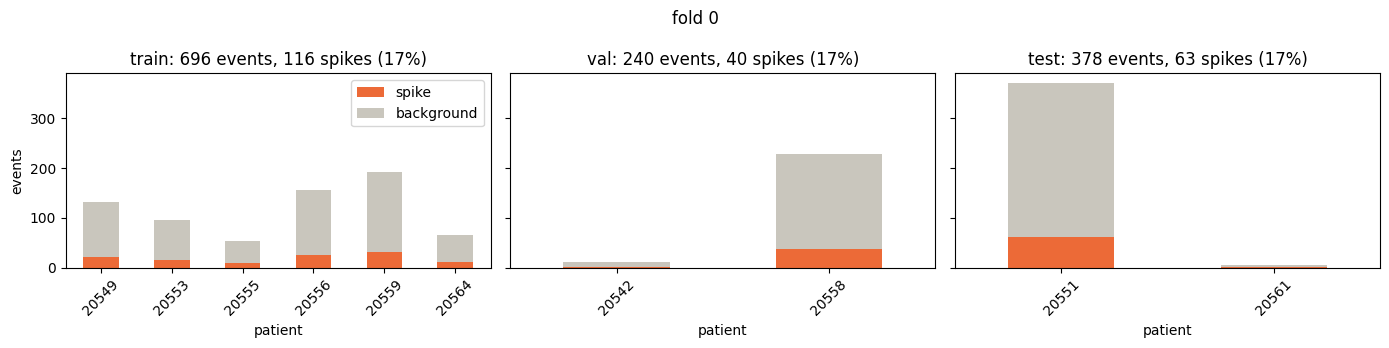

In [9]:
def split_fold(k):
    d = pd.read_csv(f'{CV_DIR}/lut_all_fold{k}.csv', sep=';')
    d['patient'] = d['eeg_file'].str.split('_Run').str[0]
    return [d[d['Mode'] == m] for m in ['Train', 'Val', 'Test']]

k = 0
tr, va, te = split_fold(k)

# 1. the returned tables
for name, d in zip(['train', 'val', 'test'], [tr, va, te]):
    print(f'--- {name}: {len(d)} rows'); display(d.head(3))

# 2. events / spikes per split and per patient
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a, name, d in zip(ax, ['train', 'val', 'test'], [tr, va, te]):
    c = d.groupby('patient')['fraction_of_yes'].agg(spike=lambda x: (x >= 0.5).sum(), background=lambda x: (x < 0.5).sum())
    c.plot.bar(stacked=True, ax=a, color=['#ec6a37', '#c9c6bd'], legend=(a is ax[0]))
    a.set_title(f"{name}: {len(d)} events, {int(c['spike'].sum())} spikes ({c['spike'].sum() / len(d):.0%})")
    a.set_xlabel('patient'); a.tick_params(axis='x', rotation=45)
ax[0].set_ylabel('events'); fig.suptitle(f'fold {k}'); plt.tight_layout(); plt.show()

In [10]:
def run_train(loader, model, loss_fn, optimizer):
    model.train()
    total = 0.0
    for x, y in loader:
        x, y = x.float().to(device), y.float().to(device).view(-1)
        loss = loss_fn(model(x).view(-1), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * x.size(0)
    return total / len(loader.dataset)

def run_val(loader, model, loss_fn):
    model.eval()
    total = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.float().to(device), y.float().to(device).view(-1)
            total += loss_fn(model(x).view(-1), y).item() * x.size(0)
    return total / len(loader.dataset)

def train_model(train_dataloader, val_dataloader, model, optimizer, loss_fn, tag='r0'):
    hist = []
    best_val = float('inf')
    bad = 0
    ckpt = f'{model_path}/best_{tag}.pt'               # one FILE, used for save, load and return
    model.to(device)
    for epoch in range(MAX_EPOCHS):
        tr = run_train(train_dataloader, model, loss_fn, optimizer)
        va = run_val(val_dataloader, model, loss_fn)
        hist.append((tr, va))
        save_curves(hist, run_path, tag)              # curves go to the run FOLDER (fine)
        log.info(f'[{tag}] epoch {epoch+1} | train {tr:.4f} | val {va:.4f}')
        if va < best_val or epoch == 0:               # epoch 0: always have a checkpoint
            best_val, bad = va, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if epoch + 1 >= MIN_EPOCHS and bad >= PATIENCE:
                log.info(f'[{tag}] early stop at epoch {epoch+1}'); break
    model.load_state_dict(torch.load(ckpt, map_location=device))   # back to the best epoch
    log.info(f'[{tag}] done | best val {best_val:.4f} | ckpt {ckpt}')
    return model, ckpt, hist

In [11]:
transform_train_pos = transforms.Compose([cut_and_jitter(windowsize=config.WINDOWSIZE,max_offset=0.1,Fq=config.FQ), 
                                      channel_flip(p=0.5),
                                      extremes_remover(signal_max = 2000, signal_min = 20)
                                      #random_channel_zero(p=0.1),
                                      #noise_adder(s=0.1, p=0.1)
                                      ])

transform_train_neg = transforms.Compose([cut_and_jitter(windowsize=config.WINDOWSIZE,max_offset=0.1,Fq=config.FQ), 
                                      channel_flip(p=0.5),
                                      #random_channel_zero(p=0.1),
                                      #noise_adder(s=0.1, p=0.1),
                                      extremes_remover(signal_max = 2000, signal_min = 20)
                                      ])

transform_val = transforms.Compose([cut_and_jitter(windowsize=config.WINDOWSIZE,max_offset=0,Fq=config.FQ),
                                    extremes_remover(signal_max = 2000, signal_min = 20)])#,CDAC_signal_flip(p=0)])


output range: 0.045330919325351715 0.7585930228233337


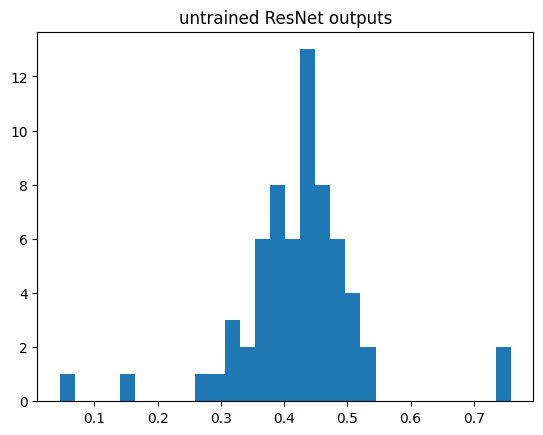

In [16]:
@torch.no_grad()
def predict(loader, model):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(model(x.float().to(device)).view(-1).cpu())
        Y.append(y.view(-1))
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def new_model():
    m = ResNet(lr=config.LR, n_channels=config.N_CHANNELS, Focal_loss=False).to(device)
    return m, torch.optim.Adam(m.parameters(), lr=config.LR)

def cb_loss_fn(labels, beta, gamma=0.0):
    """Class-balanced (focal) BCE on probabilities: the model already applies a sigmoid."""
    n = np.bincount(np.asarray(labels), minlength=2)
    w = (1 - beta) / (1 - beta ** n)
    w = torch.tensor(2 * w / w.sum(), dtype=torch.float32, device=device)
    def loss(p, y):
        y = y.float(); p = p.clamp(1e-7, 1 - 1e-7)
        bce = F.binary_cross_entropy(p, y, reduction='none')
        pt = torch.where(y >= 0.5, p, 1 - p)
        return (w[(y >= 0.5).long()] * (1 - pt) ** gamma * bce).mean()
    return loss, w.cpu().numpy()

def make_train_loader(d):
    d = d.sort_values('fraction_of_yes', ascending=False).reset_index(drop=True)
    ds = Hardmine_BonoboDataset(d, CLIPS, transform=transform_train_pos, transform_pos=transform_train_pos,
                                transform_neg=transform_train_neg, montage=combine_montage,
                                window_size=config.WINDOWSIZE, num_pos_augmentations=1)
    return DataLoader(ds, batch_size=config.BATCH_SIZE, shuffle=True, num_workers=os.cpu_count())

def make_eval_loader(d):
    ds = BonoboDataset(d, CLIPS, transform=transform_val, montage=combine_montage, window_size=config.WINDOWSIZE)
    return DataLoader(ds, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=os.cpu_count())

m, _ = new_model(); x, _ = next(iter(make_eval_loader(df.head(64))))
out = m(x.float().to(device)).detach().cpu().view(-1)
print('output range:', out.min().item(), out.max().item())
plt.hist(out.numpy(), bins=30); plt.title('untrained ResNet outputs'); plt.show()

In [17]:
def run_fold(k):
    tr, va, te = split_fold(k)
    val_dl, H, res, model = make_eval_loader(va), ctrl_mine.iloc[:0], [], None
    for r in range(len(TAUS) + 1):
        if r > 0:
            H = pd.concat([H, mine(model, set(H['event_file']), TAUS[r-1])], ignore_index=True)
            print(f'fold {k} round {r}: mined {len(H)} hard events')
        cur = pd.concat([tr, H], ignore_index=True)
        print(f'fold {k} round {r}: {len(cur)} train events')
        loss_fn, w = cb_loss_fn((cur['fraction_of_yes'] >= 0.5).astype(int), beta=0.999)   # weights for THIS round
        log.info(f'fold {k} round {r}: {len(cur)} train | class weights {w.round(3)}')
        model, optimizer = new_model()
        model, ckpt, hist = train_model(make_train_loader(pd.concat([tr, H], ignore_index=True)),
                                        val_dl, model, optimizer, loss_fn, tag=f'{METHOD}_f{k}_r{r}')
        p, y = predict(val_dl, model)
        res.append(dict(fold=k, round=r, n_hard=len(H), val_auroc=roc_auc_score(y >= 0.5, p), ckpt=ckpt))
        log.info(f'fold {k} round {r}: |H|={len(H)} val AUROC {res[-1]["val_auroc"]:.3f}')
    return pd.DataFrame(res), va, te

In [19]:
ctrl_loader, fp_loader = make_eval_loader(ctrl_mine), make_eval_loader(ctrl_fp)

def mine(model, H_names, rule):
    p, _ = predict(ctrl_loader, model)
    cand = ctrl_mine.assign(p=p)[~ctrl_mine['event_file'].isin(H_names)]
    new = cand[cand['p'] > rule] if isinstance(rule, float) else cand.nlargest(rule, 'p')   # float = τ (paper), int = top-K
    plt.hist(p, bins=50, log=True); plt.axvline(new['p'].min() if len(new) else rule, c='r')
    plt.title(f'rule={rule}: {len(new)} new'); plt.show()
    return new.drop(columns='p')

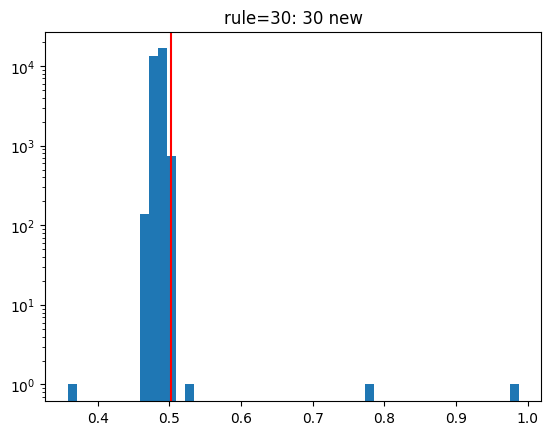

In [ ]:
# trained model from the fold-0 run
mdl, _ = new_model()
new = mine(mdl, set(), 30)
p_all, _ = predict(ctrl_loader, mdl)
new = new.assign(p=p_all[new.index]).sort_values('p', ascending=False)
print(len(new), 'hard negatives'); display(new[['event_file', 'patient', 't', 'p']].head(10))

# 1. where they come from: per patient, over time
fig, ax = plt.subplots(figsize=(12, 2.5))
for pt, c in zip(MINE_PTS, ['C0', 'C1']):
    s = ctrl_mine.assign(p=p_all)[lambda d: d['patient'] == pt]
    ax.plot(s.reset_index().index, s['p'], c=c, lw=0.5, label=pt)
ax.axhline(0.3, c='r', ls='--'); ax.set_xlabel('window # (0.25 s steps)'); ax.set_ylabel('p(spike)'); ax.legend(); plt.show()

# 2. the top 4 clips, as the model sees them (montage, central 1 s)
top = new.head(4)
xs, _ = next(iter(make_eval_loader(top)))
fig, axs = plt.subplots(1, 4, figsize=(18, 5), sharey=True)
for a, xi, (_, r) in zip(axs, xs.numpy(), top.iterrows()):
    off = 3 * xi.std() + 1e-6
    a.plot(xi[:10].T + np.arange(10) * off, lw=0.8)
    a.set_title(f"{r['event_file']}\np = {r['p']:.2f}", fontsize=8); a.set_yticks([])
plt.tight_layout(); plt.show()

In [ ]:
def evaluate_fold(res, va, te):
    best = res.loc[res['val_auroc'].idxmax()]
    model, _ = new_model(); model.load_state_dict(torch.load(best['ckpt'], map_location=device))
    pv, yv = predict(make_eval_loader(va), model); fpr_v, tpr_v, th = roc_curve(yv >= 0.5, pv)
    t = th[np.argmax(tpr_v - fpr_v)]
    pt, yt = predict(make_eval_loader(te), model); yt = yt >= 0.5; hat = pt >= t
    pf, _ = predict(fp_loader, model)
    k = int(best['fold'])
    out = dict(fold=k, best_round=int(best['round']), thr=t,
               auroc=roc_auc_score(yt, pt), auprc=average_precision_score(yt, pt),
               sens=(hat & yt).sum() / yt.sum(), spec=(~hat & ~yt).sum() / (~yt).sum(),
               f1=f1_score(yt, hat), fp_per_hr=(pf >= t).sum() / (len(ctrl_fp) * 0.25 / 3600))

    # ROC + PR on the test set
    fpr, tpr, _ = roc_curve(yt, pt); prec, rec, _ = precision_recall_curve(yt, pt)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    
    ax[0].plot(fpr, tpr, label=f"AUROC {out['auroc']:.3f}"); ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax[0].scatter(1 - out['spec'], out['sens'], c='r', zorder=3, label=f'threshold {t:.2f}')
    ax[0].set_xlabel('false positive rate')
    ax[0].set_ylabel('true positive rate')
    ax[0].set_title(f'fold {k} test ROC')

    ax[1].plot(rec, prec, label=f"AUPRC {out['auprc']:.3f}")
    ax[1].axhline(yt.mean(), c='k', ls='--', lw=0.8, label=f'chance {yt.mean():.2f}')
    ax[1].set_xlabel('recall')
    ax[1].set_ylabel('precision')
    ax[1].set_title(f'fold {k} test PR')
    for a in ax: a.legend(loc='lower right' if a is ax[0] else 'upper right'); a.set_xlim(0, 1); a.set_ylim(0, 1.02)
    plt.tight_layout(); plt.savefig(f'{run_path}/test_roc_f{k}.png'); plt.show()

    out['_curve'] = (fpr, tpr)
    return out

In [ ]:
TAUS = [0.7]
METHOD = 'sanity'
res0, va0, te0 = run_fold(0)
display(res0); 
display(evaluate_fold(res0, va0, te0))
plt.imshow(plt.imread(f'{run_path}/loss_{METHOD}_f0_r0.png')); plt.axis('off'); plt.show()

In [ ]:
METHOD = 'thr'                       # 'thr' = paper τ schedule, 'topk' = top-K
TAUS = [100, 200, 400]      # few, most-confident errors first, then progressively more and subtler ones

all_res, metrics, metrics_r0 = [], [], []
for k in range(5):
    res, va, te = run_fold(k)
    all_res.append(res)
    metrics.append(evaluate_fold(res, va, te))               # best round on val (with mining)
    metrics_r0.append(evaluate_fold(res.iloc[[0]], va, te))  # round 0 only = no mining
    pd.concat(all_res).to_csv(f'{run_path}/{METHOD}_rounds.csv', index=False)
    for name, m in [(METHOD, metrics), (f'{METHOD}_nomine', metrics_r0)]:
        pd.DataFrame(m).drop(columns='_curve').to_csv(f'{run_path}/{name}_cv5_metrics.csv', index=False)

# summary: no mining vs mining
cols = ['auroc', 'auprc', 'sens', 'spec', 'f1', 'fp_per_hr']
S = pd.DataFrame({name: pd.DataFrame(m)[cols].agg(['mean', 'std']).round(3).apply(lambda c: f"{c['mean']} ± {c['std']}")
                  for name, m in [('no mining', metrics_r0), (METHOD, metrics)]}).T
display(S)
print('best round per fold:', [m['best_round'] for m in metrics])

# val AUROC per round
for r in all_res: plt.plot(r['round'], r['val_auroc'], marker='o', label=f"fold {r['fold'].iloc[0]}")
plt.xlabel('round'); plt.ylabel('val AUROC'); plt.legend(); plt.show()

# combined test ROC over folds
grid = np.linspace(0, 1, 201); tprs = []
for m in metrics:
    fpr, tpr = m['_curve']; tprs.append(np.interp(grid, fpr, tpr))
    plt.plot(fpr, tpr, lw=0.8, alpha=0.5, label=f"fold {m['fold']} ({m['auroc']:.2f})")
mean, sd = np.mean(tprs, 0), np.std(tprs, 0)
plt.plot(grid, mean, 'k', lw=2, label=f"mean {np.mean([m['auroc'] for m in metrics]):.3f}")
plt.fill_between(grid, mean - sd, mean + sd, color='k', alpha=0.1); plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate'); plt.title(f'CV5 test ROC ({METHOD})')
plt.legend(fontsize=8); plt.savefig(f'{run_path}/{METHOD}_test_roc_cv5.png'); plt.show()